# Module 7 — Two-Layer Neural Network with Backpropagation
**ECE 5831: Pattern Recognition and Neural Networks — Fall 2026**

This notebook implements and compares two ways of training the same two-layer network on MNIST:

1. **`TwoLayerNetBackprop`** — written from scratch in NumPy; gradients computed with the **backpropagation** algorithm (chain rule through the affine, ReLU and softmax-with-loss layers).
2. **`TwoLayerNetKeras`** — the same architecture built with **TensorFlow/Keras**, where automatic differentiation computes the gradients.

Both use the same setup so the comparison is fair:

| Setting | Value |
|---|---|
| Architecture | 784 → 100 (ReLU) → 10 (Softmax) |
| Loss | Cross-entropy |
| Optimizer | Mini-batch SGD, learning rate 0.1 |
| Batch size / Epochs | 64 / 10 |
| Weight init | 0.01 · N(0, 1), zero biases (backprop version) |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Load and prepare the MNIST dataset
Each 28×28 image is flattened to a 784-dimensional vector and scaled to [0, 1]. Labels are one-hot encoded for the cross-entropy loss.

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Original shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

# Flatten and normalize
X_train = X_train.reshape(60000, 784).astype("float32") / 255.0
X_test = X_test.reshape(10000, 784).astype("float32") / 255.0

# One-hot encoding
y_train_onehot = np.eye(10)[y_train]
y_test_onehot = np.eye(10)[y_test]

print("\nAfter preprocessing:")
print("X_train:", X_train.shape, "| y_train_onehot:", y_train_onehot.shape)
print("X_test :", X_test.shape, "| y_test_onehot :", y_test_onehot.shape)

Original shapes:
X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)



After preprocessing:
X_train: (60000, 784) | y_train_onehot: (60000, 10)
X_test : (10000, 784) | y_test_onehot : (10000, 10)


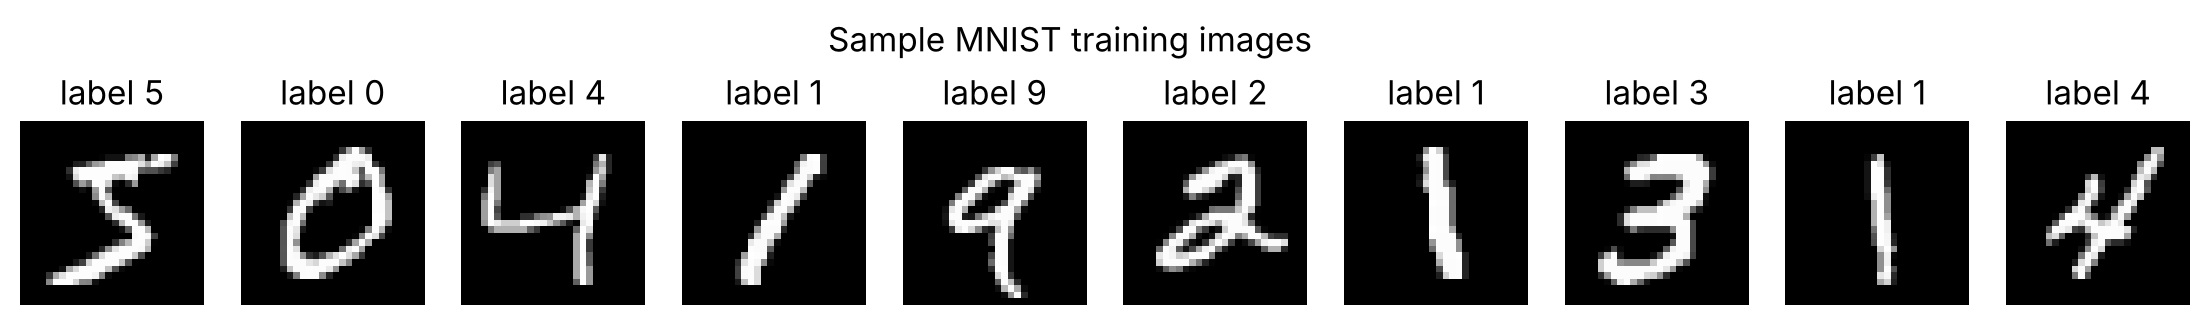

In [3]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"label {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST training images")
plt.show()

## 2. `TwoLayerNetBackprop` — NumPy implementation

**Forward propagation** (batch of inputs $X$, shape $N \times 784$):

$$A_1 = XW_1 + b_1,\qquad Z_1 = \mathrm{ReLU}(A_1),\qquad A_2 = Z_1W_2 + b_2,\qquad \hat{Y} = \mathrm{softmax}(A_2)$$

$$L = -\frac{1}{N}\sum_{n}\sum_{k} y_{nk}\log \hat{y}_{nk}$$

**Backpropagation** (chain rule, applied layer by layer from the output back to the input):

| Layer | Local gradient |
|---|---|
| Softmax + cross-entropy | $\dfrac{\partial L}{\partial A_2} = \dfrac{\hat{Y} - Y}{N}$ |
| Affine 2 | $\dfrac{\partial L}{\partial W_2} = Z_1^{T}\dfrac{\partial L}{\partial A_2}$, $\;\dfrac{\partial L}{\partial b_2} = \sum_n \dfrac{\partial L}{\partial A_2}$, $\;\dfrac{\partial L}{\partial Z_1} = \dfrac{\partial L}{\partial A_2}W_2^{T}$ |
| ReLU | $\dfrac{\partial L}{\partial A_1} = \dfrac{\partial L}{\partial Z_1} \odot \mathbb{1}[A_1 > 0]$ |
| Affine 1 | $\dfrac{\partial L}{\partial W_1} = X^{T}\dfrac{\partial L}{\partial A_1}$, $\;\dfrac{\partial L}{\partial b_1} = \sum_n \dfrac{\partial L}{\partial A_1}$ |

The bias gradients sum over the batch axis — this is the batch version of the affine-layer backward pass.

In [4]:
class TwoLayerNetBackprop:
    # Two-layer fully connected network trained with backpropagation (NumPy only).

    def __init__(self, input_size=28*28, hidden_size=100, output_size=10, weight_init_std=0.01):
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)

    # ---------- activation functions ----------
    def relu(self, s):
        return np.maximum(0, s)

    def relu_grad(self, s):
        grad = np.zeros_like(s)
        grad[s > 0] = 1
        return grad

    def softmax(self, s):
        if s.ndim == 1:
            s = s - np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        s = s - np.max(s, axis=1, keepdims=True)   # subtract max for numerical stability
        exp_s = np.exp(s)
        return exp_s / np.sum(exp_s, axis=1, keepdims=True)

    # ---------- forward propagation ----------
    def predict(self, x):
        w1, b1 = self.params["w1"], self.params["b1"]
        w2, b2 = self.params["w2"], self.params["b2"]
        a1 = x @ w1 + b1          # Layer 1 (affine)
        z1 = self.relu(a1)        # ReLU
        a2 = z1 @ w2 + b2         # Layer 2 (affine)
        return self.softmax(a2)   # Output probabilities

    # ---------- loss ----------
    def cross_entropy_error(self, y, yhat):
        if y.ndim == 1:
            y = y.reshape(1, y.size)
            yhat = yhat.reshape(1, yhat.size)
        batch_size = y.shape[0]
        return -np.sum(y * np.log(yhat + 1e-7)) / batch_size

    def loss(self, x, y):
        return self.cross_entropy_error(y, self.predict(x))

    def accuracy(self, x, y_labels):
        return np.mean(np.argmax(self.predict(x), axis=1) == y_labels)

    # ---------- backpropagation ----------
    def gradient(self, x, y):
        w1, b1 = self.params["w1"], self.params["b1"]
        w2, b2 = self.params["w2"], self.params["b2"]
        if x.ndim == 1:
            x = x.reshape(1, -1)
        if y.ndim == 1:
            y = y.reshape(1, -1)
        batch_size = x.shape[0]

        # Forward pass (keep intermediate values for the backward pass)
        a1 = x @ w1 + b1
        z1 = self.relu(a1)
        a2 = z1 @ w2 + b2
        yhat = self.softmax(a2)

        # Backward pass
        da2 = (yhat - y) / batch_size        # softmax + cross-entropy
        dw2 = z1.T @ da2                     # affine 2
        db2 = np.sum(da2, axis=0)
        dz1 = da2 @ w2.T                     # back to hidden layer
        da1 = dz1 * self.relu_grad(a1)       # ReLU
        dw1 = x.T @ da1                      # affine 1
        db1 = np.sum(da1, axis=0)

        return {"w1": dw1, "b1": db1, "w2": dw2, "b2": db2}

    # ---------- numerical gradient (used only to verify backprop) ----------
    def numerical_gradient(self, x, y, h=1e-4):
        grads = {}
        for key, param in self.params.items():
            grad = np.zeros_like(param)
            it = np.nditer(param, flags=["multi_index"], op_flags=["readwrite"])
            while not it.finished:
                idx = it.multi_index
                tmp = param[idx]
                param[idx] = tmp + h
                f_plus = self.loss(x, y)
                param[idx] = tmp - h
                f_minus = self.loss(x, y)
                grad[idx] = (f_plus - f_minus) / (2 * h)
                param[idx] = tmp
                it.iternext()
            grads[key] = grad
        return grads

### 2.1 Gradient check — backprop vs. numerical gradient
Before training, the analytic gradients from backpropagation are compared against the central-difference numerical gradient (from Module 6) on a small network and a few samples. A mean absolute difference near $10^{-9}$ or smaller confirms the backward pass is correct.

In [5]:
np.random.seed(0)
check_net = TwoLayerNetBackprop(input_size=784, hidden_size=10, output_size=10, weight_init_std=0.1)
x_check, y_check = X_train[:3].astype(np.float64), y_train_onehot[:3]

grad_backprop = check_net.gradient(x_check, y_check)
grad_numerical = check_net.numerical_gradient(x_check, y_check)

for key in ["w1", "b1", "w2", "b2"]:
    diff = np.mean(np.abs(grad_backprop[key] - grad_numerical[key]))
    print(f"{key}: mean |backprop - numerical| = {diff:.3e}")

w1: mean |backprop - numerical| = 4.889e-09
b1: mean |backprop - numerical| = 3.480e-08
w2: mean |backprop - numerical| = 5.587e-08
b2: mean |backprop - numerical| = 1.475e-07


### 2.2 Train `TwoLayerNetBackprop`

In [6]:
# Training settings
epochs = 10
learning_rate = 0.1
batch_size = 64

np.random.seed(42)
network = TwoLayerNetBackprop(input_size=28*28, hidden_size=100, output_size=10)

bp_history = {"loss": [], "accuracy": [], "test_loss": [], "test_accuracy": []}
start = time.time()

for epoch in range(epochs):
    # Shuffle training data each epoch
    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    y_shuffled = y_train_onehot[indices]

    # Mini-batch SGD
    for i in range(0, len(X_train), batch_size):
        x_batch = X_shuffled[i:i+batch_size]
        y_batch = y_shuffled[i:i+batch_size]
        grad = network.gradient(x_batch, y_batch)       # backpropagation
        for key in network.params:
            network.params[key] -= learning_rate * grad[key]

    # Track metrics on the full training and test sets
    bp_history["loss"].append(network.loss(X_train, y_train_onehot))
    bp_history["accuracy"].append(network.accuracy(X_train, y_train))
    bp_history["test_loss"].append(network.loss(X_test, y_test_onehot))
    bp_history["test_accuracy"].append(network.accuracy(X_test, y_test))

    print(f"Epoch {epoch+1:2d}/{epochs} | "
          f"Train loss: {bp_history['loss'][-1]:.4f} | Train acc: {bp_history['accuracy'][-1]:.4f} | "
          f"Test loss: {bp_history['test_loss'][-1]:.4f} | Test acc: {bp_history['test_accuracy'][-1]:.4f}")

bp_train_time = time.time() - start
print(f"\nTraining time: {bp_train_time:.1f} s")

Epoch  1/10 | Train loss: 0.2872 | Train acc: 0.9174 | Test loss: 0.2760 | Test acc: 0.9216


Epoch  2/10 | Train loss: 0.2031 | Train acc: 0.9437 | Test loss: 0.2010 | Test acc: 0.9418


Epoch  3/10 | Train loss: 0.1743 | Train acc: 0.9493 | Test loss: 0.1786 | Test acc: 0.9459


Epoch  4/10 | Train loss: 0.1318 | Train acc: 0.9624 | Test loss: 0.1410 | Test acc: 0.9585


Epoch  5/10 | Train loss: 0.1105 | Train acc: 0.9686 | Test loss: 0.1199 | Test acc: 0.9635


Epoch  6/10 | Train loss: 0.0974 | Train acc: 0.9721 | Test loss: 0.1090 | Test acc: 0.9659


Epoch  7/10 | Train loss: 0.0835 | Train acc: 0.9769 | Test loss: 0.0995 | Test acc: 0.9692


Epoch  8/10 | Train loss: 0.0749 | Train acc: 0.9789 | Test loss: 0.0954 | Test acc: 0.9703


Epoch  9/10 | Train loss: 0.0784 | Train acc: 0.9785 | Test loss: 0.1053 | Test acc: 0.9688


Epoch 10/10 | Train loss: 0.0621 | Train acc: 0.9824 | Test loss: 0.0868 | Test acc: 0.9723

Training time: 16.5 s


### 2.3 Training curves

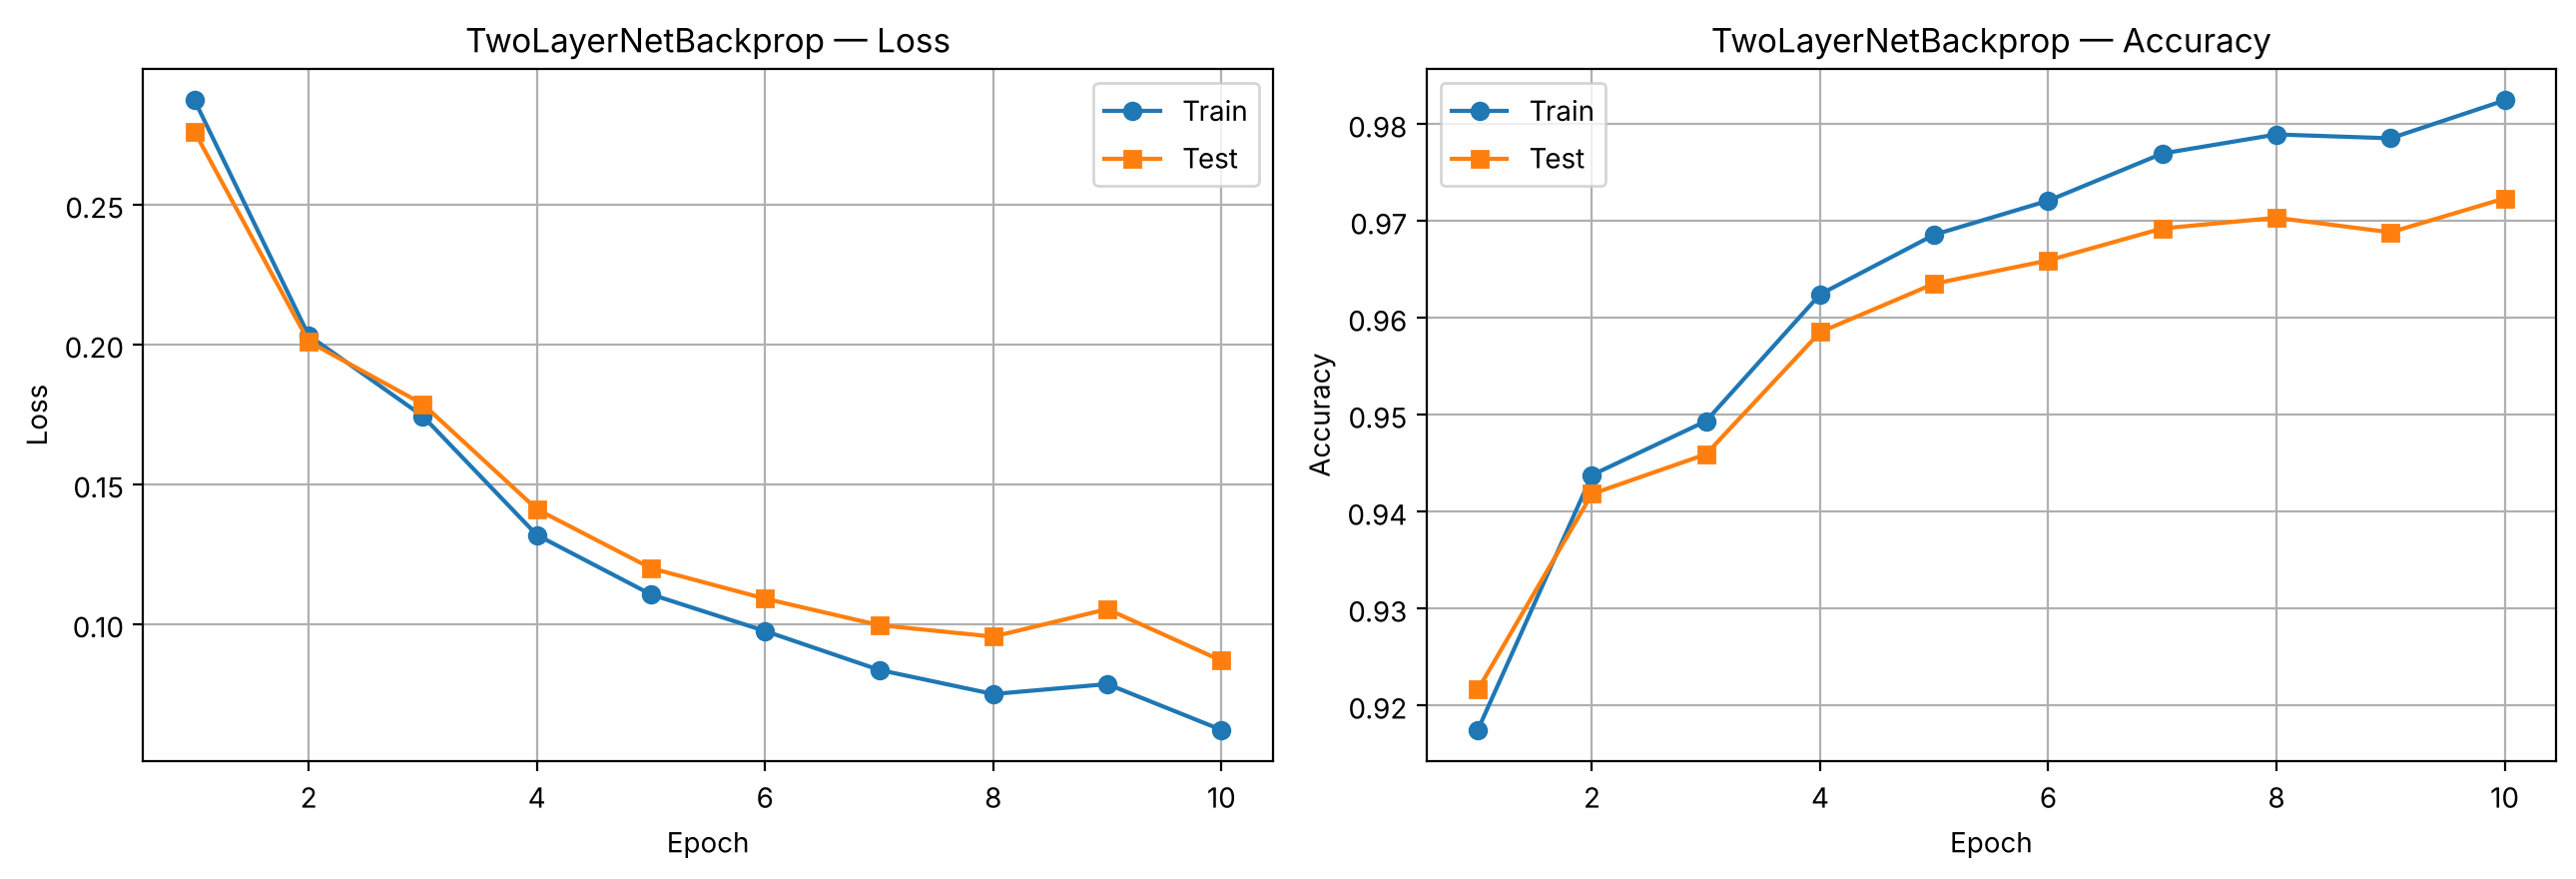

In [7]:
ep = range(1, epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(ep, bp_history["loss"], marker="o", label="Train")
ax1.plot(ep, bp_history["test_loss"], marker="s", label="Test")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("TwoLayerNetBackprop — Loss")
ax1.grid(); ax1.legend()

ax2.plot(ep, bp_history["accuracy"], marker="o", label="Train")
ax2.plot(ep, bp_history["test_accuracy"], marker="s", label="Test")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_title("TwoLayerNetBackprop — Accuracy")
ax2.grid(); ax2.legend()
plt.tight_layout()
plt.show()

### 2.4 Test `TwoLayerNetBackprop`

In [8]:
y_test_pred = network.predict(X_test)
predicted_test_class = np.argmax(y_test_pred, axis=1)

bp_test_loss = network.loss(X_test, y_test_onehot)
bp_test_accuracy = np.mean(predicted_test_class == y_test)
bp_train_accuracy = network.accuracy(X_train, y_train)

print(f"Train Accuracy: {bp_train_accuracy:.4f}")
print(f"Test Loss     : {bp_test_loss:.4f}")
print(f"Test Accuracy : {bp_test_accuracy:.4f}")

Train Accuracy: 0.9824
Test Loss     : 0.0868
Test Accuracy : 0.9723


**A single test case**

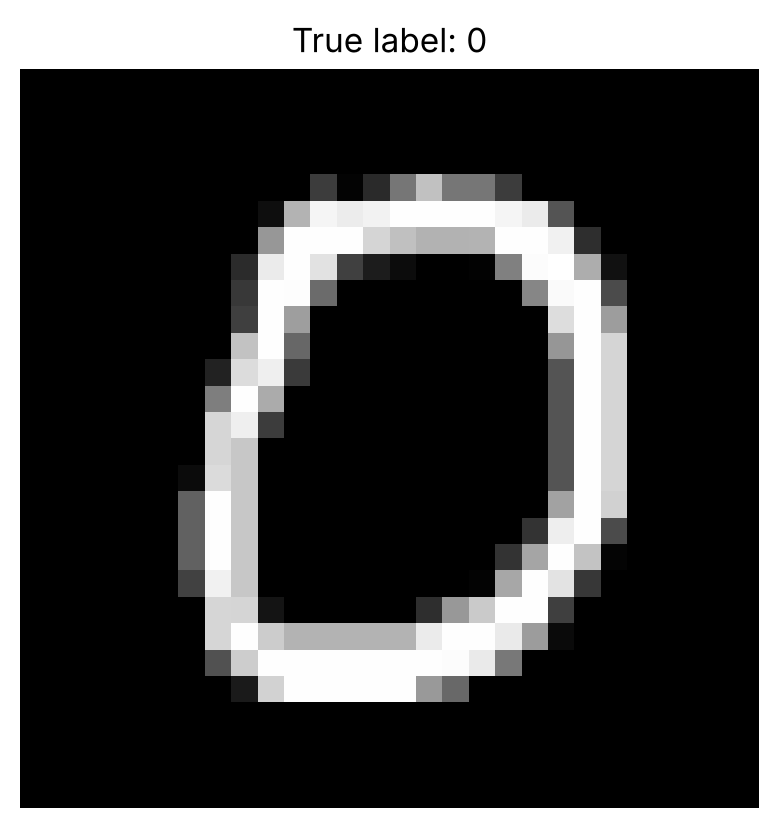

prediction: 0 | true label: 0


In [9]:
idx = 10
plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
plt.title(f"True label: {y_test[idx]}")
plt.axis("off")
plt.show()
print("prediction:", y_test_pred[idx].argmax(), "| true label:", y_test[idx])

## 3. `TwoLayerNetKeras` — Keras implementation
The same 784 → 100 → 10 network built from `Dense` layers. Following the Keras workflow from the lecture:
- **Model** — a graph of layers (`Dense(100, relu)` → `Dense(10, softmax)`)
- **`compile()`** — choose the loss (categorical cross-entropy), optimizer (SGD, lr = 0.1) and metric (accuracy)
- **`fit()`** — the training loop (epochs, batch size)
- **`predict()` / `evaluate()`** — inference on new data

Keras computes the gradients with automatic differentiation — backpropagation done by the framework.

In [10]:
class TwoLayerNetKeras:
    # Same two-layer network built and trained with TensorFlow/Keras.

    def __init__(self, input_size=28*28, hidden_size=100, output_size=10, learning_rate=0.1):
        self.model = keras.Sequential([
            keras.Input(shape=(input_size,)),
            layers.Dense(hidden_size, activation="relu", name="hidden"),
            layers.Dense(output_size, activation="softmax", name="output"),
        ])
        self.model.compile(
            optimizer=keras.optimizers.SGD(learning_rate=learning_rate),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )

    def train(self, x, y, epochs=10, batch_size=64, validation_data=None, verbose=2):
        return self.model.fit(x, y, epochs=epochs, batch_size=batch_size,
                              validation_data=validation_data, shuffle=True, verbose=verbose)

    def predict(self, x):
        return self.model.predict(x, verbose=0)

    def evaluate(self, x, y):
        return self.model.evaluate(x, y, verbose=0)   # returns [loss, accuracy]

    def summary(self):
        self.model.summary()


keras_net = TwoLayerNetKeras(input_size=28*28, hidden_size=100, output_size=10, learning_rate=learning_rate)
keras_net.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

### 3.1 Train `TwoLayerNetKeras`

In [11]:
start = time.time()
history = keras_net.train(X_train, y_train_onehot, epochs=epochs, batch_size=batch_size,
                          validation_data=(X_test, y_test_onehot))
keras_train_time = time.time() - start
print(f"\nTraining time: {keras_train_time:.1f} s")

Epoch 1/10


938/938 - 2s - 2ms/step - accuracy: 0.8975 - loss: 0.3693 - val_accuracy: 0.9320 - val_loss: 0.2332


Epoch 2/10


938/938 - 1s - 1ms/step - accuracy: 0.9422 - loss: 0.2029 - val_accuracy: 0.9470 - val_loss: 0.1724


Epoch 3/10


938/938 - 1s - 1ms/step - accuracy: 0.9561 - loss: 0.1541 - val_accuracy: 0.9583 - val_loss: 0.1391


... (11 outputs left out)

938/938 - 2s - 2ms/step - accuracy: 0.9822 - loss: 0.0653 - val_accuracy: 0.9739 - val_loss: 0.0863


Epoch 10/10


938/938 - 1s - 1ms/step - accuracy: 0.9841 - loss: 0.0593 - val_accuracy: 0.9752 - val_loss: 0.0840



Training time: 15.2 s


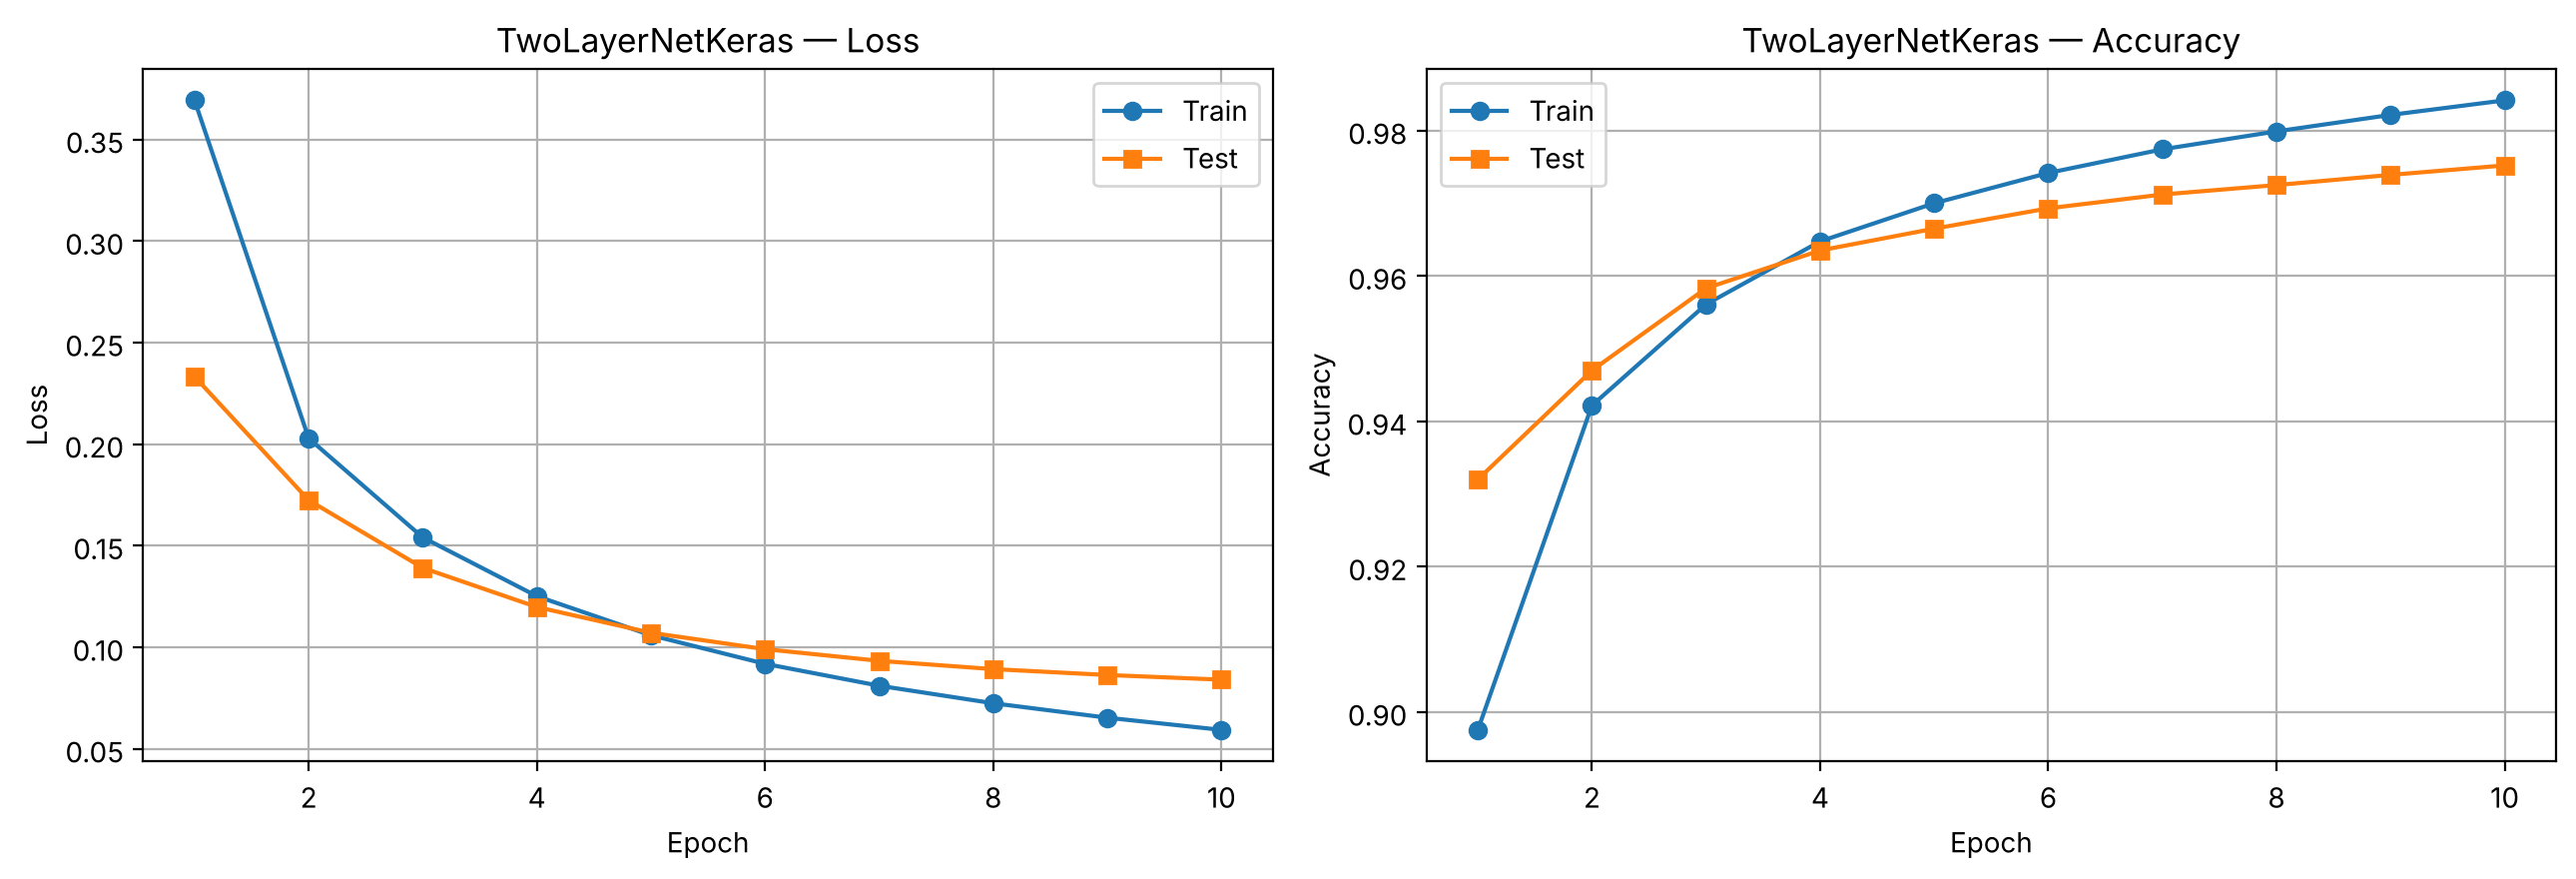

In [12]:
kh = history.history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(ep, kh["loss"], marker="o", label="Train")
ax1.plot(ep, kh["val_loss"], marker="s", label="Test")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("TwoLayerNetKeras — Loss")
ax1.grid(); ax1.legend()

ax2.plot(ep, kh["accuracy"], marker="o", label="Train")
ax2.plot(ep, kh["val_accuracy"], marker="s", label="Test")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.set_title("TwoLayerNetKeras — Accuracy")
ax2.grid(); ax2.legend()
plt.tight_layout()
plt.show()

### 3.2 Test `TwoLayerNetKeras`

In [13]:
keras_test_loss, keras_test_accuracy = keras_net.evaluate(X_test, y_test_onehot)
_, keras_train_accuracy = keras_net.evaluate(X_train, y_train_onehot)
keras_pred = keras_net.predict(X_test)

print(f"Train Accuracy: {keras_train_accuracy:.4f}")
print(f"Test Loss     : {keras_test_loss:.4f}")
print(f"Test Accuracy : {keras_test_accuracy:.4f}")
print("\nSingle test case (index 10) prediction:", keras_pred[10].argmax(), "| true label:", y_test[10])

Train Accuracy: 0.9862
Test Loss     : 0.0840
Test Accuracy : 0.9752

Single test case (index 10) prediction: 0 | true label: 0


## 4. Comparison: Backpropagation (NumPy) vs. Keras

In [14]:
print(f"{'Model':<22}{'Train Acc':>11}{'Test Acc':>11}{'Test Loss':>11}{'Time (s)':>10}")
print("-" * 65)
print(f"{'TwoLayerNetBackprop':<22}{bp_train_accuracy:>11.4f}{bp_test_accuracy:>11.4f}{bp_test_loss:>11.4f}{bp_train_time:>10.1f}")
print(f"{'TwoLayerNetKeras':<22}{keras_train_accuracy:>11.4f}{keras_test_accuracy:>11.4f}{keras_test_loss:>11.4f}{keras_train_time:>10.1f}")

agree = np.mean(predicted_test_class == keras_pred.argmax(axis=1))
print(f"\nThe two models give the same prediction on {agree*100:.2f}% of the test images.")

Model                   Train Acc   Test Acc  Test Loss  Time (s)
-----------------------------------------------------------------
TwoLayerNetBackprop        0.9824     0.9723     0.0868      16.5
TwoLayerNetKeras           0.9862     0.9752     0.0840      15.2

The two models give the same prediction on 98.17% of the test images.


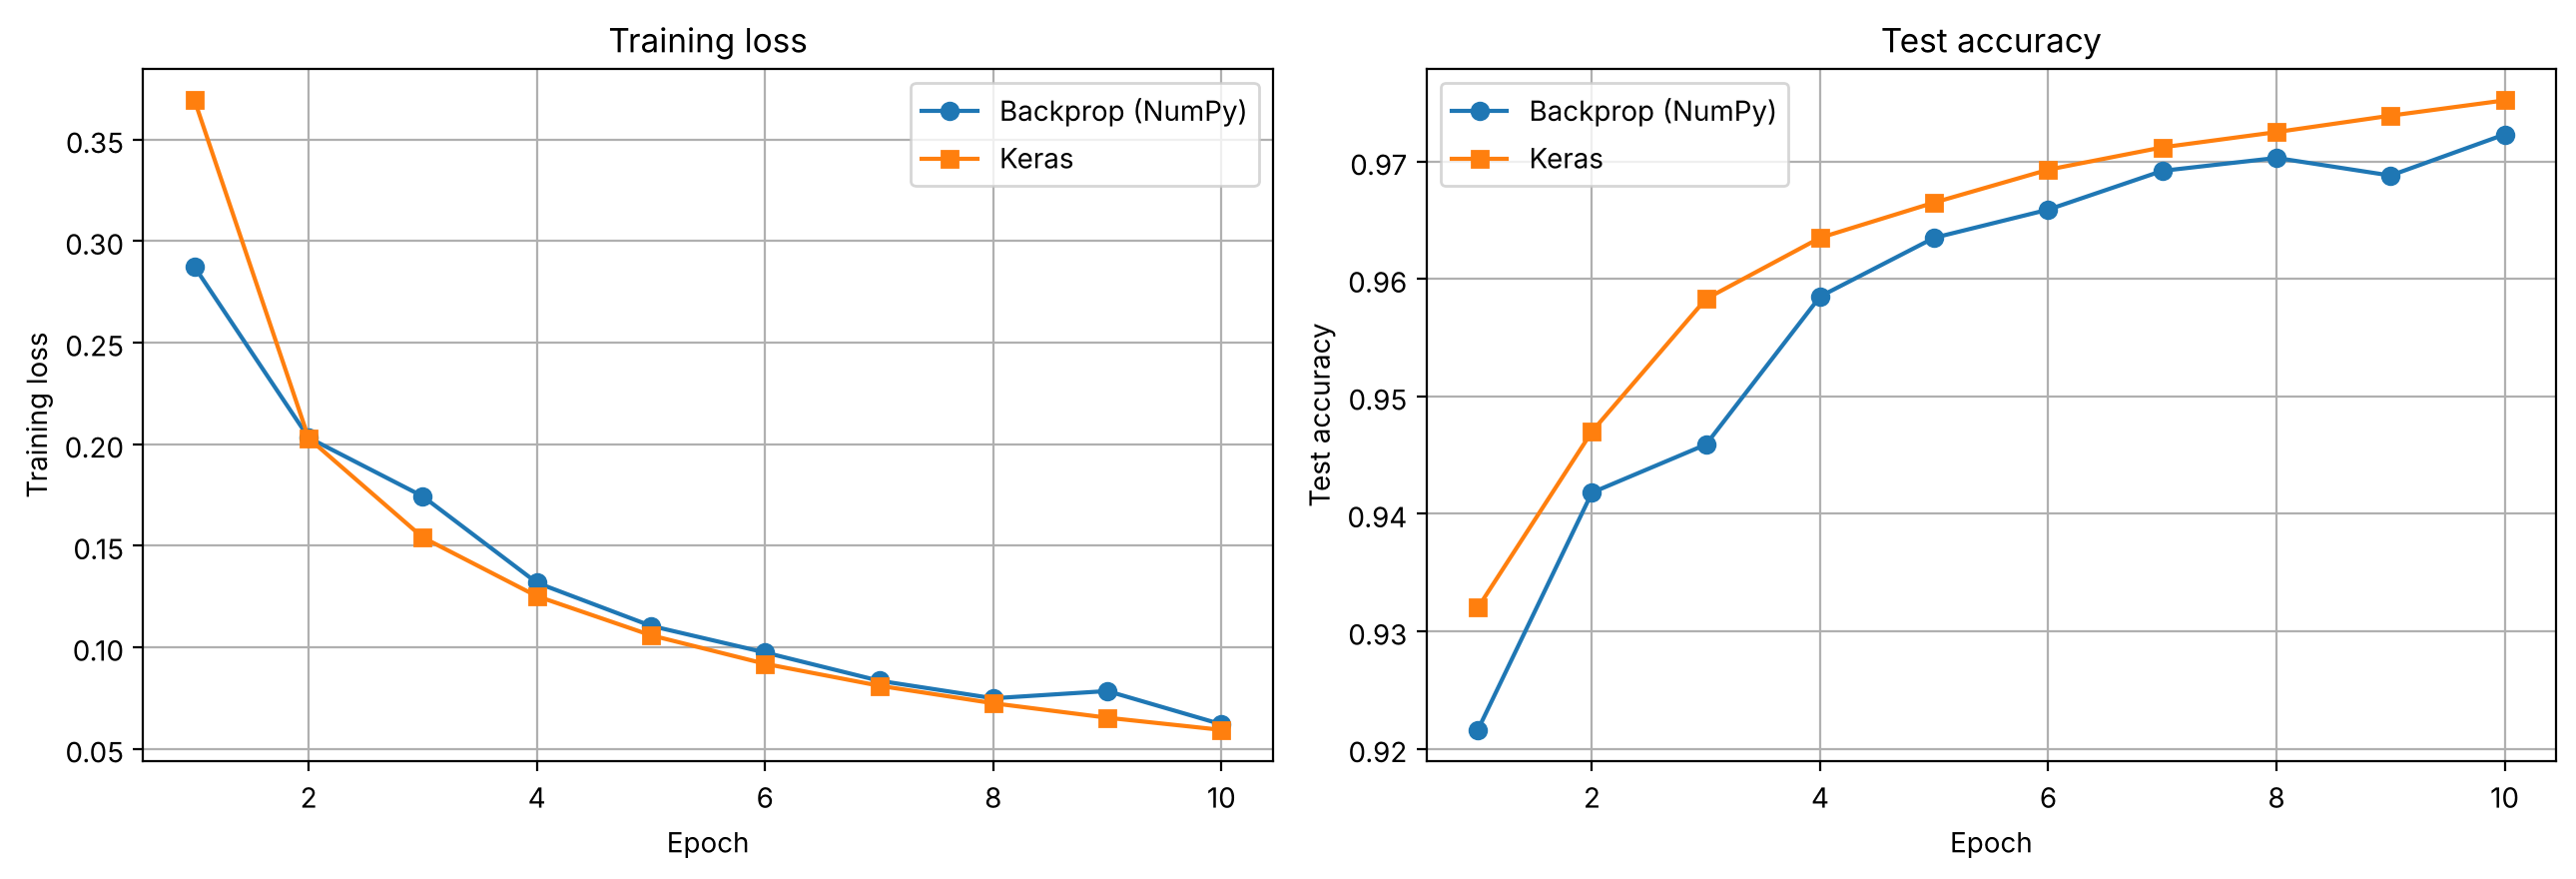

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(ep, bp_history["loss"], marker="o", label="Backprop (NumPy)")
ax1.plot(ep, kh["loss"], marker="s", label="Keras")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Training loss"); ax1.set_title("Training loss")
ax1.grid(); ax1.legend()

ax2.plot(ep, bp_history["test_accuracy"], marker="o", label="Backprop (NumPy)")
ax2.plot(ep, kh["val_accuracy"], marker="s", label="Keras")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Test accuracy"); ax2.set_title("Test accuracy")
ax2.grid(); ax2.legend()
plt.tight_layout()
plt.show()

### Sample test predictions (both models)

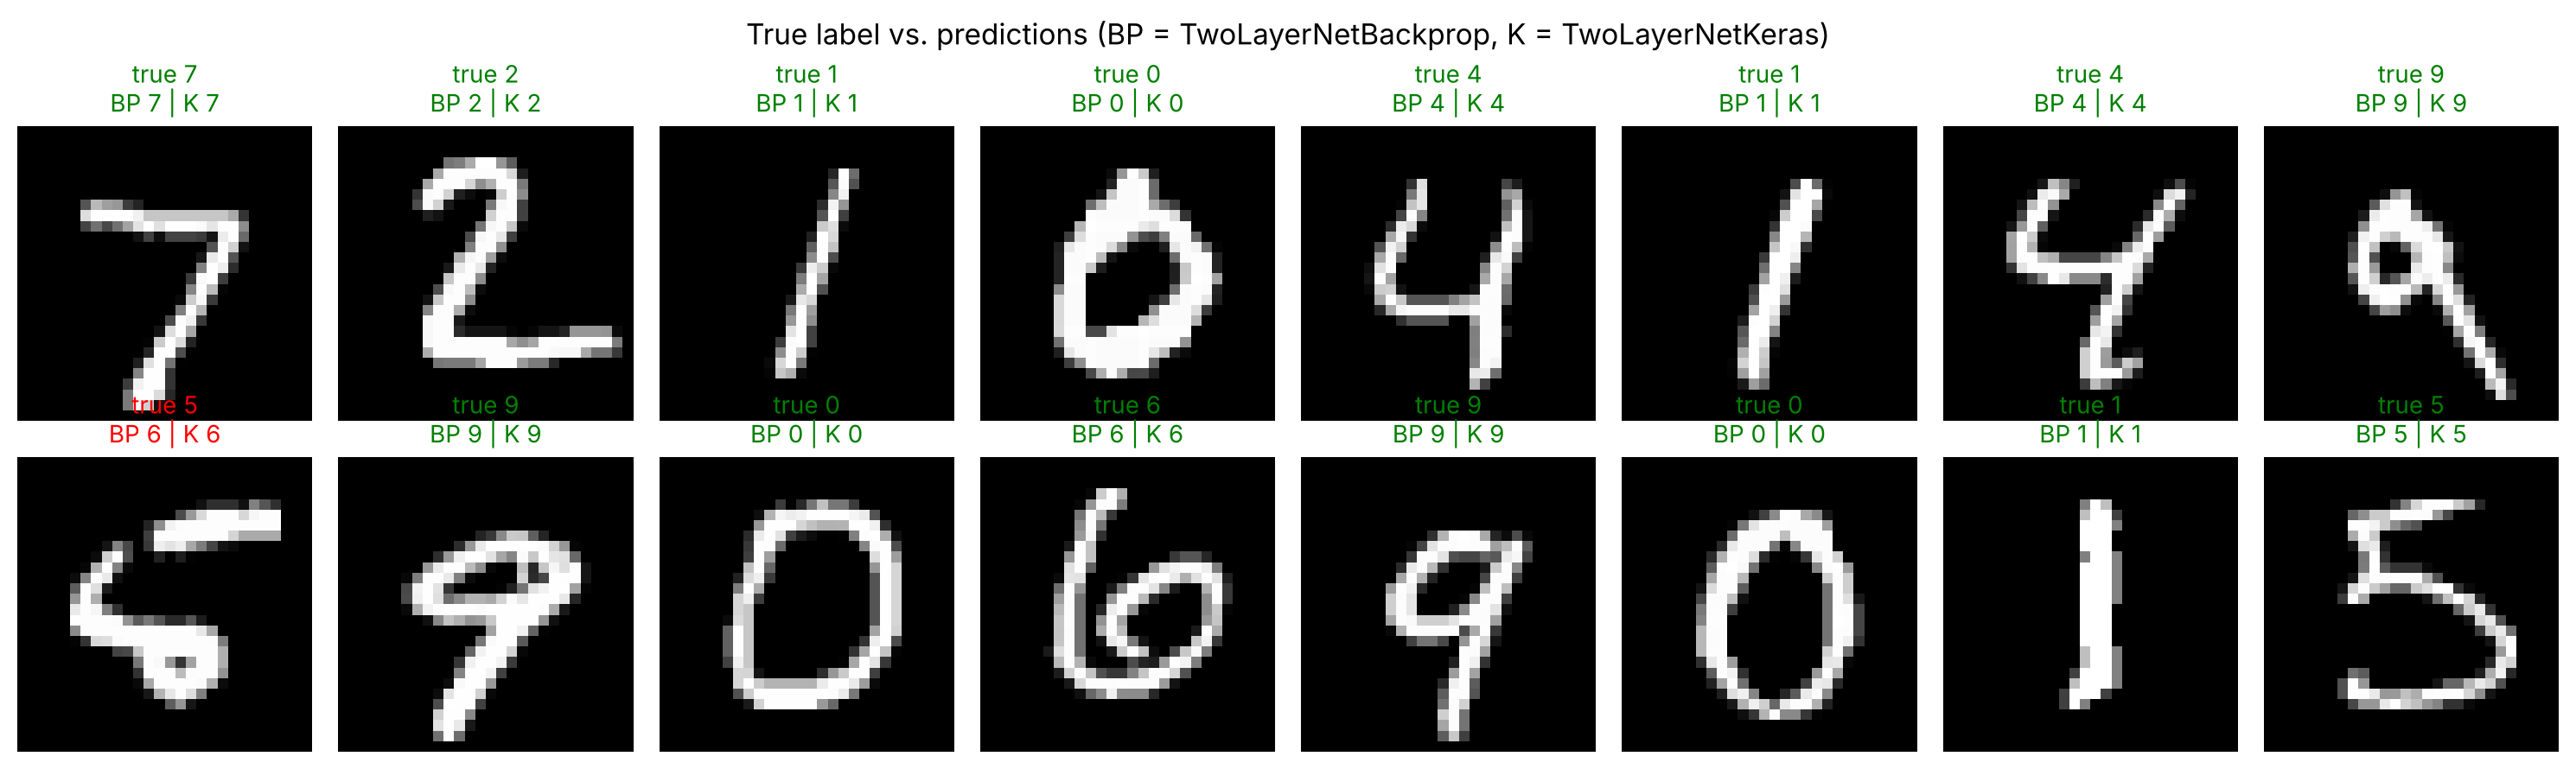

In [16]:
fig, axes = plt.subplots(2, 8, figsize=(15, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    bp_p, k_p = predicted_test_class[i], keras_pred[i].argmax()
    color = "green" if (bp_p == y_test[i] and k_p == y_test[i]) else "red"
    ax.set_title(f"true {y_test[i]}\nBP {bp_p} | K {k_p}", color=color, fontsize=10)
    ax.axis("off")
plt.suptitle("True label vs. predictions (BP = TwoLayerNetBackprop, K = TwoLayerNetKeras)")
plt.tight_layout()
plt.show()

## 5. Conclusion

In [17]:
print(f"TwoLayerNetBackprop test accuracy: {bp_test_accuracy*100:.2f}%")
print(f"TwoLayerNetKeras    test accuracy: {keras_test_accuracy*100:.2f}%")

TwoLayerNetBackprop test accuracy: 97.23%
TwoLayerNetKeras    test accuracy: 97.52%


- **`TwoLayerNetBackprop` trains and tests successfully.** The gradient check shows the backpropagation gradients match the numerical gradients almost exactly, and the network reaches roughly 97–98% test accuracy after 10 epochs (exact values printed above).
- **`TwoLayerNetKeras` reaches about the same accuracy** with the same architecture and hyperparameters, which confirms the hand-written forward and backward passes do what the framework does. Small differences come from weight initialization (Keras uses Glorot-uniform by default instead of 0.01·N(0,1)) and random shuffling.
- **Backpropagation vs. numerical gradient:** backprop gets all gradients from one forward and one backward pass. The numerical gradient needs two forward passes *per parameter* (~159k parameters here), which is far too slow for training. That is why backpropagation is used in practice.
- **NumPy vs. Keras:** the NumPy version shows each step of the algorithm. Keras hides the low-level tensor operations and differentiation, so the code is shorter and easier to scale to bigger models and GPUs.